# 25 数据关联规则挖掘

> **模块**：关联规则 ｜ **数据**：`tr.xlsx`、`rule1.xlsx` ｜ **依赖**：numpy、pandas

## 1. 学习目标

- 了解关联规则相关的基本概念
- 掌握关联规则挖掘的基本流程和算法
- 掌握Apriori算法的实现过程


## 2. 内容导览
1. 关联规则概念
2. 关联规则挖掘
3. Apriori算法


## 3. 关联规则概念

### 3.1 关联规则概念

- “啤酒与尿布”的故事：美国沃尔玛拥有世界上最大的数据仓库系统，为了能够准确地了解顾客的购买习惯，沃尔玛对顾客购物行为进行了购物篮分析，想知道顾客经常一起购买的商品都有哪些。沃尔玛数据仓库里集中了详细的原始交易数据。在这些原始交易数据的基础上，沃尔玛利用数据挖掘方法对这些数据进行分析和挖掘。一个意外的发现是：与尿布一起购买最多的商品竟是啤酒。经过大量实际调查分析，揭示了一个隐藏的规律：在美国，一些年轻的父亲下班后经常要到超市去买婴儿尿布，而他们中有30%~40%的人同时也为自己买一些啤酒。产生这一现象的原因是：美国太太们常叮嘱她们的丈夫下班后为小孩买尿布，而丈夫们在买尿布后又随手带回了他们喜欢的啤酒。
- 这种“啤酒与尿布”的关联关系在现实中广泛存在，比如人们的穿衣搭配、产品交叉销售、各种营销推荐方案等，归结起来它们就是一种关联规则问题。

假设有以下数据集，每行代表一个顾客在超市的购买记录：

- I1: 西红柿、排骨、鸡蛋
- I2: 西红柿、茄子
- I3: 鸡蛋、袜子
- I4: 西红柿、排骨、茄子
- I5: 西红柿、排骨、袜子、酸奶
- I6: 鸡蛋、茄子、酸奶
- I7: 排骨、鸡蛋、茄子
- I8: 土豆、鸡蛋、袜子
- I9: 西红柿、排骨、鞋子、土豆

假如有一条规则：西红柿 -> 排骨，则同时购买西红柿和排骨的顾客比例为 4/9，而购买西红柿的顾客当中也购买了排骨的比例是 4/5。这两个比例参数在关联规则中是非常有意义的度量，分别称作支持度（support）和置信度（confidence）。支持度反映了规则的覆盖范围，置信度反映了规则的可信程度。

在关联规则挖掘中，如上例所有商品集合 I={西红柿，排骨，鸡蛋，茄子，袜子，酸奶，土豆，鞋子}称作项集，每一个顾客购买的商品集合 I称为一个事务，所有事务 T={I1, I2, …, I9}称作事务集合，且满足 I 是 T 的真子集。

### 3.2 项集和频繁项集

- 项集：项集是项的集合。包含 k 个项的项集成为 k 项集，如集合 {牛奶, 麦片, 糖} 是一个 3 项集。
- 支持度计数：项集 A 的支持度计数是事务数据集中包含项集 A 的事务个数，简称为项集的频率或计数。
- 频繁项集：项集的出现频率是所有包含项集的事务计数，又称为绝对支持度或支持度计数。如果项集的支持度满足预定义的最小支持度阈值，则称其为频繁项集。频繁 k 项集通常记作 Lk。

### 3.3 支持度、置信度和提升度

- 支持度 (Support): 表示某个项集出现的频率，也就是包含该项集的交易数与总交易数的比例。
- 置信度 (Confidence): 表示当 A 项出现时 B 项同时出现的频率，记作 {A -> B}。换言之，置信度指同时包含 A 项和 B 项的交易数与包含 A 项的交易数之比。
- 提升度 (Lift): 指 A 项和 B 项一同出现的频率，但同时要考虑这两项各自出现的频率。提升度反映了关联规则中的 A 与 B 的相关性。提升度 > 1 且越高表示正相关性越高，提升度 < 1 且越低表明负相关性越高，提升度 = 1 表明没有相关性。负值表示商品之间是相互排斥的。

### 3.4 关联规则

形式如下：
- A、B 满足：A、B 是 T 的真子集，并且 A 和 B 的交集为空集。其中 A 称为前件，B 称为后件。关联规则有时也可以表示为“如果 A，那就 B”，前者是规则成立的条件，后者是条件下发生的结果。支持度和置信度有以下计算公式：

$$
Support (A \rightarrow B) = \frac{A, B 同时发生的事务个数}{所有事务个数}

$$

$$
Confidence (A \Rightarrow B) = P(A | B) = \frac{Support(A \cap B)}{Support(A)} = \frac{支持度计数 (A \cap B)}{支持度(A)}

$$

- 支持度表示为项集 A、B 同时发生的概率，而置信度则表示为项集 A 发生的条件下项集 B 发生的概率。

### 3.5 最小支持度和最小置信度

- 最小支持度是用户或专家定义的衡量支持度的一个阈值，表示项集在统计意义上的最低重要性；
- 最小置信度是用户或专家定义的衡量置信度的一个阈值，表示关联规则的最低可靠性；
- 同时满足最小支持度阈值和最小置信度阈值的规则称作强关联规则。


## 4. 关联规则挖掘

### 4.1 布尔关联规则挖掘

- 布尔关联规则挖掘是指将事务数据集转化为布尔 (0 或 1) 值数据集，并在布尔数据集基础上挖掘关联规则的一种方法。在布尔数据集上挖掘关联规则的取值要么是 0，要么是 1，计算关联规则的支持度和置信度仅通过求和运算即可完成。
- 将超市购买记录的例子转化为布尔值数据集，每一行仍然代表一个事务，即购买记录；列为项，即购买的商品名称。取值 0 表示该事务在对应的项中没有出现，即没有购买该商品，否则为 1。

> *原稿配图未随 notebook 保存，此处暂缺。*

**布尔关联规则挖掘又分为一对一关联规则和多对一关联规则。**

01 一对一关联规则:
一对一关联规则是指规则的前件和后件都只有一项，即“A->B“这种形式。这种关联规则的挖掘相对简单，直接利用关联规则支持度和置信度的计算公式计算即可。

02 多对一关联规则:
多对一关联规则是指前件有多个项，而后件只有一个项的关联规则，即“A,B->C“这种形式。多对一关联规则在应用中具有非常积极的意义，但是挖掘起来比较困难，特别是大规模的问题，寻找到感兴趣的关联规则可能需要耗费极大的计算精力。

**利用 Python 3.10 实现一对一关联规则挖掘的具体流程及思路如下：**

1.将事务数据集转化为布尔(0、1)值数据表，算法如下：

首先，定义一个空的字典D和包含所有商品的列表，例如item=['西红柿'，排骨'，鸡蛋'，'茄子'，袜子'，酸奶'，土豆，鞋子]。

其次，定义一个长度与数据集长度（事务个数）相同的一维全0数组z,循环操作商品列表itm,对每一个商品，搜索其所在事务序号（行号），并将事务序号对应的z位置修改为1，同时以商品作为键，z作为值,添加到字典D中。

最后，将D转化为数据框。

2.利用关联规则的置信度定义和支持度定义，挖掘两项之间的关联规则。

1.事务数据集转化为布尔(0、1)值数据表，示例代码如下：


In [1]:
item = ['西红柿', '排骨', '鸡蛋', '茄子', '袜子', '酸奶', '土豆', '鞋子']

import pandas as pd
import numpy as np

# 读取Excel文件
data = pd.read_excel('../data/tr.xlsx', header=None)

# 动态生成列名
data.columns = [f'item{i+1}' for i in range(data.shape[1])]

# 创建一个字典来存储分组的数据
D = {}
for item_name in item:
    z = np.zeros((len(data)))  # 初始化一个零数组作为默认值
    li = list()  # 初始化一个空列表用于存储匹配项的索引
    for i in range(len(data)):  # 遍历数据
        if data.iloc[i, 0] == item_name:  # 如果当前行的item1列值等于item_name
            li.append(i)  # 将索引添加到列表中
    D[item_name] = z[li]  # 将匹配项的索引对应的值存储到字典中
    print(f'处理 {item_name}: {D[item_name]}')  # 输出结果

# 创建一个新的DataFrame，数据为之前创建的字典D的值
Data = pd.DataFrame(D)


处理 西红柿: []
处理 排骨: []
处理 鸡蛋: []
处理 茄子: []
处理 袜子: []
处理 酸奶: []
处理 土豆: []
处理 鞋子: []


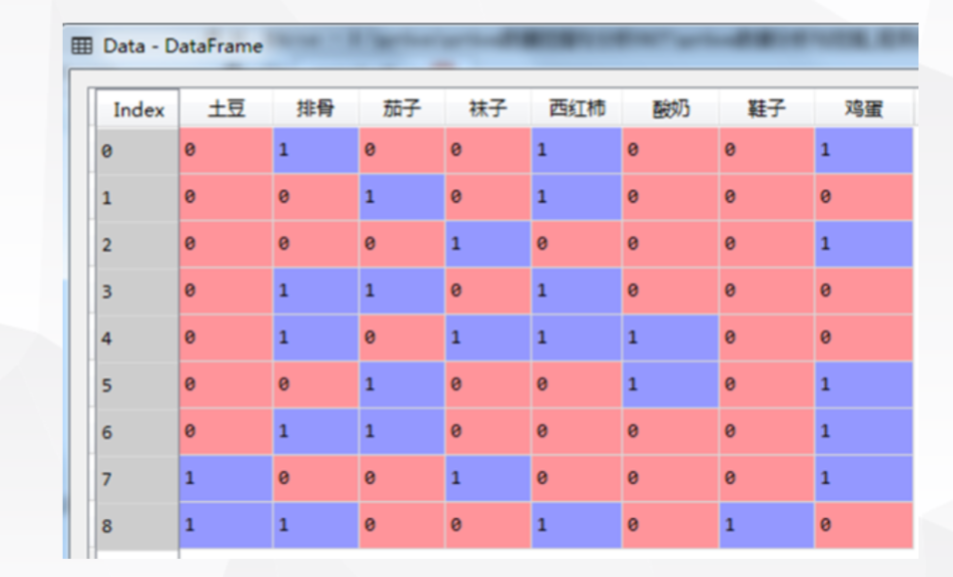

2.利用关联规则的置信度定义和支持度定义，挖掘两项之间的关联规则，示例代码如下：

In [2]:
# 导入所需的库
import pandas as pd
import numpy as np

# 数据读取（请确保你的文件路径正确）
# 注意：Jupyter Notebook的文件路径是相对于Notebook所在的文件夹
Data = pd.read_excel('../data/tr.xlsx')  

# 获取数据的列名
c = list(Data.columns)
c0 = 0.5  # 设置最小置信度
s0 = 0.2  # 设置最小支持度

# 初始化列表来存储规则、支持度和置信度
list1, list2, list3 = [], [], []

# 遍历每一对列来发现关联规则
for k in range(len(c)):
    for q in range(len(c)):
        if c[k] != c[q]:  # 确保不是同一列
            # 创建布尔掩码来表示每个元素是否等于1
            antecedent = (Data[c[k]] == 1).values
            consequent = (Data[c[q]] == 1).values
            
            # 计算联合出现次数
            t12 = np.logical_and(antecedent, consequent)
            t1 = antecedent
            
            # 计算支持度和置信度，并添加到列表中
            if t1.sum() > 0:  # 避免除零错误
                sp = t12.sum() / len(Data)  # 支持度
                co = t12.sum() / t1.sum()   # 置信度
                
                if co >= c0 and sp >= s0:
                    list1.append(f"{c[k]} → {c[q]}")
                    list2.append(round(sp, 4))
                    list3.append(round(co, 4))

# 创建DataFrame来存储结果
R = pd.DataFrame({
    'Rule': list1,
    'Support': list2,
    'Confidence': list3
})

# 使用ExcelWriter导出结果到Excel文件
with pd.ExcelWriter('../data/rule1.xlsx', engine='openpyxl') as writer:
    R.to_excel(writer, index=False)
print("输出成功：../data/rule1.xlsx")


输出成功：../data/rule1.xlsx


> *原稿配图未随 notebook 保存，此处暂缺。*

### 4.2 关联规则算法

关联规则实际上包含两个子任务：

- 频繁模式发现：也称频繁模式挖掘、频繁项挖掘等，是指从一系列候选的项中选择频繁的部分，通常衡量
频繁的程度可以是对每一项出现的频率，当超过某一阈值是则认为这个项是频繁的。
- 生成关联规则：在已经发现的最大频繁项目集中，寻找置信度不小于用户给定的最小置信度的关联规则。

常用的关联规则算法包括：Apriori算法、FP Tree:算法、Eclati算法、灰色关联法等

- Apiori算法：关联规则最常用的也是最经典的挖掘频繁项集的算法。其核心思想是通过连接产生候选项及其支持度，然后通过剪枝生成频繁项集。
- FP-Tree算法：针对Apriori算法的固有多次扫描事务数据集的缺陷，提出的不产生候选项频繁项集的方法。Aprioriz和FP-Tree都是寻找频繁项集的算法。
- Eclt算法：是一种深度优先算法，采用垂直数据表示形式，在概念格理论的基础上利用基于前缀的等价关系将搜索空间划分为较小的空间。
- 灰色关联法：分析和确定各因素之间的影响程度或是若干个因素（子序列）对主因素（母序列）的贡献度而进行的一种分析方法。
---


## 5. Apriori 算法

Apriori算法是一种关联规则挖掘的经典算法，针对中小规模的关联规则挖掘问题具有较好的适用性。Apriori算法由R.Agrawal和R.Srikant于l994年提出，该算法的主要思想是找出存在于事务数据集中的最大频繁项集，在利用得到的最大频繁项集与预先设定的最小置信度阈值生成强关联规则。

> *原稿配图未随 notebook 保存，此处暂缺。*

### 5.1 Apriori 算法具体过程如下

- Step1:设置预定的最小支持度阈值及最小置信度阈值；
- Step2：在研究数据中找出所有频繁项集（支持度必须大于等于给定的最小支持度阈值），在这个过程中连接步和剪枝步互相融合，最终得到最大频繁项集L;

(1)连接步。目的是找到K项集。对给定的最小支持度阈值，分别对1项候选集C1,剔除小于该阈值的项集得到1项频繁集L1；下一步由L1自身连接产生2项候选集C2,保留C2中满足约束条件的项集得到2项频繁集，记为L2；再由下一步由L2与L1连接产生3项候选集C3，保留C3中满足约束条件的项集得到3项频繁集，记作L3…这样循环下去，得到最大频繁项集。（这里运用到关联规则中的置信度和支持度的计算公式）。

(2)剪枝步。紧接着连接步，在产生候选项的过程中起到减小搜索空间的目的。由于Ck是L与L连接产生的，根据Apio的性质频繁集的所有频繁项集的所有非空子集也必须是频繁项集，所有不满足该性质的项集不会存在于Ck中，该过程就是剪枝。

- Step3：由频繁项集产生强关联规则，经过程Step2可知未超过预定的最小支持度阈值的项集已经被剔除，如果剩下这些规则又满足了预定的最小置信度阈值，那么就挖掘出了强关联规则。

综合以上所述，根据支持度和置信度两个指标，我们可以准确并稳定地衡量某条关联规则，也正因此我们需要根据实际情况设定相应的最小支持度和最小置信度，就可以筛选出符合我们要求的关联规则。

### 5.2 基于频繁项集产生关联规则

由关联规则置信度的计算公式：

$$ C o n f i d e n c e ( A \Rightarrow B ) = P ( B | A ) = \frac { S u p p o r t ( A \cap B ) } { S u p p o r t ( A ) } = \frac { S u p p o r t \_ c o u n t ( A \cap B ) } { S u p p o r t ( A ) }$$

可以利用其支持度计数来计算关联规则的置信度，比如由上图中的1频繁项集L1和2频繁项集L2可以获得以下
关联规则的置信度：
排骨一>茄子 confidence=2/5
排骨一>西红柿 confidence=4/5
排骨一>鸡蛋 confidence=2/5
茄子一>西红柿 confidence=2/5
茄子一>鸡蛋 confidence=2/5
袜子一>鸡蛋 confidence=2/3

### 5.3 Apriori 算法特点

简单且易于实现，是最具代表性的关联规则挖掘算法,随着数据集规模的不断增长，逐渐显现出一定的局限性：
- 需多次扫描数据库，很大的/O负载，算法的执行效率较低；
- 产生大量的候选项目集，尤其是候选2-项集占用内存非常大，会消耗大量的内存；
- 对于每一趟扫描，只有当内存大小足够容纳需要进行计数的候选集时才能正确执行。如果内存不够大，要么使用一种空间复杂度更小的算法，要么只能对一个候选集进行多次扫描，否则将会出现“内存抖动”的情况，即在一趟扫描中页面频繁地移进移出内存（页面置换算法也无法避免内存抖动问题），造成运行时间的剧增。

> *原稿配图未随 notebook 保存，此处暂缺。*

### 5.4 Apriori 关联规则挖掘算法应用举例（一）

- 以超市购买记录数据为例，利用关联规则挖掘算法挖掘其关联规则。将其数据整理到一个E℃表格中（文件命名为tr.lsx),其形式如下：

> *原稿配图未随 notebook 保存，此处暂缺。*

### 5.5 Apriori 关联规则挖掘算法应用举例（二）

- 首先利用前面讲述的Python程序代码，将以上事务数据转换为布尔值数据表，记为Data,然后调用aprioriB函数即可挖掘其关联规则，示例代码如下：

> *原稿配图未随 notebook 保存，此处暂缺。*

apyori库提供的apriori方法，常用参数含义为：
- transactions:事务集合
- min_support:最小支持度，可用来筛选项集
- min confidence:最小置信度，可用来筛选项集
- min lift:最小提升度
- max_length:序列最小长度
---
END
